# K-Means and Hierarchical Clustering on the Iris Dataset

**Objective:** Implement:
- **K-Means Clustering**
- **Hierarchical Clustering** (Agglomerative, Ward linkage)
- Use the **Elbow Method** to determine the suitable number of K-Means clusters
- Use a **Dendrogram** for hierarchical clustering (cut at **K = 3**)
- Analyze the clusters using **Sum of Squared Within-Cluster Distance (WCSS)**, the **Gini Index** and the **Dunn Index**

> The `Species` column is removed before clustering, so the algorithms work on an **unlabelled** dataset.
> The species labels are kept separately only to analyse the clusters afterwards.

## 1. Import Required Libraries

The first two environment variables limit OpenMP/MKL threads. This avoids the common Windows + MKL warning where K-Means reports a possible memory leak on small datasets.

In [248]:
# Run this cell first, before importing NumPy or scikit-learn.
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment

RANDOM_STATE = 42
K = 3   # number of clusters used for every method

# One fixed colour per species, used in every plot (including the dendrogram).
# After clustering, cluster 0 = the setosa-like cluster, 1 = versicolor-like, 2 = virginica-like,
# so each cluster always gets the colour of the species it matches.
SPECIES_ORDER = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]
CLUSTER_COLORS = ["tab:blue", "tab:orange", "tab:green"]
SPECIES_COLORS = dict(zip(SPECIES_ORDER, CLUSTER_COLORS))
CLUSTER_NAMES = [f"Cluster {i} ({name.replace('Iris-', '')})" for i, name in enumerate(SPECIES_ORDER)]

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Iris Dataset

In [249]:
df = pd.read_csv("Iris.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Make the Dataset Unlabelled Before Clustering

`Species` is the known label, so it is saved separately and removed from the features.
`Id` is also removed because an identifier is not a useful clustering feature.

In [250]:
print("Number of duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

species = df["Species"].copy()
X = df.drop(columns=["Id", "Species"])

print("\nUnlabelled feature dataset shape:", X.shape)
print("Features used for clustering:", X.columns.tolist())
display(X.head())

Number of duplicate rows: 0

Missing values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Unlabelled feature dataset shape: (150, 4)
Features used for clustering: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 4. Standardize the Features and Split Training/Test Data

The rows are split into **80% training** and **20% testing** data. The scaler is fitted on the training data only
(to avoid data leakage) and then applied to the test set and the complete dataset.

In [251]:
all_indices = np.arange(len(X))
train_indices, test_indices = train_test_split(
    all_indices, test_size=0.20, random_state=RANDOM_STATE
)

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_scaled = scaler.transform(X)

print(f"Training samples: {len(train_indices)} ({len(train_indices) / len(X):.0%})")
print(f"Testing samples:  {len(test_indices)} ({len(test_indices) / len(X):.0%})")
print("\nStandardized training data:")
display(pd.DataFrame(X_train_scaled, columns=X.columns).head())

Training samples: 120 (80%)
Testing samples:  30 (20%)

Standardized training data:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-1.473937,1.220379,-1.563987,-1.309484
1,-0.133071,3.020017,-1.277280,-1.042922
2,1.085898,0.095606,0.385621,0.289886
3,-1.230143,0.770470,-1.219939,-1.309484
4,-1.717731,0.320560,-1.391963,-1.309484


## 5. Evaluation Metrics

**Sum of Squared Within-Cluster Distance (WCSS)** — how compact the clusters are (lower is better):

$$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

**Gini Index** of a cluster — how mixed the real species are inside it (0 = pure cluster):

$$Gini(C_k) = 1 - \sum_{j} p_j^2$$

The overall Gini is the weighted average of the cluster Gini values, weighted by cluster size.

**Dunn Index** — separation between clusters compared with the spread inside clusters (higher is better):

$$Dunn = \frac{\text{minimum inter-cluster distance}}{\text{maximum intra-cluster distance}}$$

In [252]:
def calculate_wcss(X_data, labels):
    wcss = 0
    for c in np.unique(labels):
        points = X_data[labels == c]
        centroid = points.mean(axis=0)
        wcss += np.sum((points - centroid) ** 2)
    return wcss


def calculate_gini(labels, true_labels):
    true_labels = pd.Series(np.asarray(true_labels))
    rows = []
    for c in np.unique(labels):
        p = true_labels[labels == c].value_counts(normalize=True)
        rows.append({
            "Cluster": c,
            "Size": int((labels == c).sum()),
            "Majority Species": p.idxmax(),
            "Gini": 1 - np.sum(p ** 2)
        })
    table = pd.DataFrame(rows).set_index("Cluster")
    weighted_gini = np.sum(table["Size"] * table["Gini"]) / table["Size"].sum()
    return table, weighted_gini


def dunn_index(X_data, labels):
    distances = pairwise_distances(X_data, metric="euclidean")
    clusters = np.unique(labels)

    # Largest distance between two points of the same cluster (cluster diameter)
    max_intra = max(
        distances[np.ix_(labels == c, labels == c)].max() for c in clusters
    )

    # Smallest distance between two points of different clusters
    min_inter = min(
        distances[np.ix_(labels == a, labels == b)].min()
        for i, a in enumerate(clusters) for b in clusters[i + 1:]
    )
    return min_inter / max_intra


def align_to_species(labels):
    """Renumber clusters so cluster 0 = setosa-like, 1 = versicolor-like, 2 = virginica-like.

    Cluster numbers from K-Means / hierarchical clustering are arbitrary. The species labels are used
    only AFTER clustering, to give each cluster a fixed number and colour (best one-to-one match).
    """
    counts = pd.crosstab(labels, species.values).reindex(columns=SPECIES_ORDER, fill_value=0)
    rows, cols = linear_sum_assignment(-counts.values)   # maximise matched samples
    mapping = np.empty(len(rows), dtype=int)
    mapping[counts.index.values[rows]] = cols
    return mapping                                       # mapping[old_cluster] = new_cluster

## 6. Visualisation Helper

Clusters are shown on **petal length vs petal width** (original cm), the two features that separate the flowers best.
Clustering itself uses **all four** standardized features.

**Fixed colours:** blue = setosa, orange = versicolor, green = virginica in every plot.
Cluster numbers from the algorithms are arbitrary, so after clustering each cluster is renumbered to match
the species it contains most (cluster 0 = setosa-like, 1 = versicolor-like, 2 = virginica-like).
The species labels are **not** used to form the clusters, only to number and colour them.

In [253]:
def show_clusters(labels, title, centers=None):
    plt.figure(figsize=(9, 6))
    for c in np.unique(labels):
        plt.scatter(X.loc[labels == c, "PetalLengthCm"], X.loc[labels == c, "PetalWidthCm"],
                    color=CLUSTER_COLORS[c], s=45, edgecolor="black", label=CLUSTER_NAMES[c])
    if centers is not None:
        centers_cm = pd.DataFrame(scaler.inverse_transform(centers), columns=X.columns)
        plt.scatter(centers_cm["PetalLengthCm"], centers_cm["PetalWidthCm"], marker="*", s=350,
                    c="red", edgecolor="black", label="Cluster centres")
    plt.xlabel("Petal Length (cm)")
    plt.ylabel("Petal Width (cm)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def show_species_table(labels, name):
    print(f"{name} vs Actual Species:")
    display(pd.crosstab(labels, species.values, rownames=["Cluster"], colnames=["Species"]))

### 6.1 Actual Species (for reference only)

This is the true grouping. The clustering algorithms never see these labels.

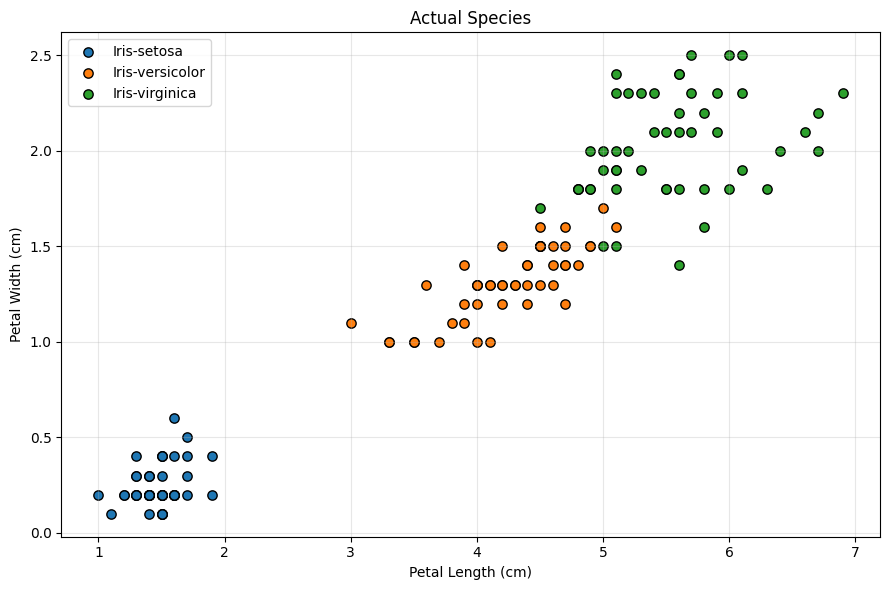

In [254]:
plt.figure(figsize=(9, 6))
for name in SPECIES_ORDER:
    plt.scatter(X.loc[species == name, "PetalLengthCm"], X.loc[species == name, "PetalWidthCm"],
                color=SPECIES_COLORS[name], s=45, edgecolor="black", label=name)
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Actual Species")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. K-Means Clustering

### 7.1 Elbow Method

K-Means is run for K = 1 to 10 and the WCSS (`inertia_`) is recorded.
The elbow is found automatically as the point with the **maximum perpendicular distance**
from the straight line joining the first and last points of the curve.

In [255]:
k_values = np.arange(1, 11)
elbow_wcss = []

for k in k_values:
    model = KMeans(n_clusters=int(k), n_init=10, random_state=RANDOM_STATE, algorithm="lloyd")
    model.fit(X_scaled)
    elbow_wcss.append(model.inertia_)

display(pd.DataFrame({"K": k_values, "WCSS": elbow_wcss}).round(3))

# Normalise both axes to 0-1, then find the point farthest from the first-last line
x_norm = (k_values - k_values.min()) / (k_values.max() - k_values.min())
y_vals = np.array(elbow_wcss)
y_norm = (y_vals - y_vals.min()) / (y_vals.max() - y_vals.min())

x1, y1, x2, y2 = x_norm[0], y_norm[0], x_norm[-1], y_norm[-1]
distances = np.abs((y2 - y1) * x_norm - (x2 - x1) * y_norm + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)

optimal_k = int(k_values[np.argmax(distances)])
optimal_wcss = elbow_wcss[optimal_k - 1]

,K,WCSS
0,1,600.241
1,2,220.548
2,3,138.116
3,4,112.668
4,5,89.467
5,6,80.350
6,7,70.442
7,8,62.700
8,9,53.905
9,10,47.166


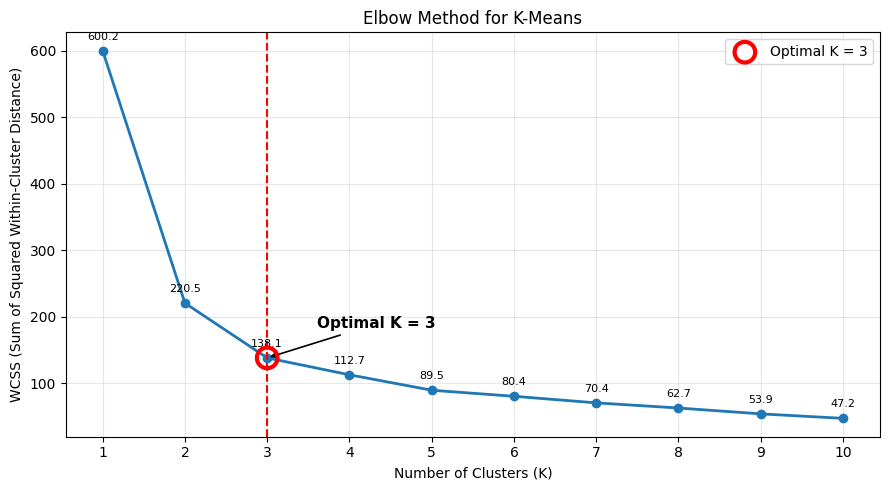

Optimal number of clusters (K) from the Elbow Method: 3


In [256]:
plt.figure(figsize=(9, 5))
plt.plot(k_values, elbow_wcss, marker="o", linewidth=2)
plt.scatter(optimal_k, optimal_wcss, s=220, facecolors="none", edgecolors="red",
            linewidths=3, zorder=5, label=f"Optimal K = {optimal_k}")
plt.axvline(optimal_k, linestyle="--", linewidth=1.5, color="red")
plt.annotate(
    f"Optimal K = {optimal_k}",
    xy=(optimal_k, optimal_wcss),
    xytext=(optimal_k + 0.6, optimal_wcss + 0.08 * (max(elbow_wcss) - min(elbow_wcss))),
    arrowprops=dict(arrowstyle="->", linewidth=1.2),
    fontsize=11, fontweight="bold"
)
for k, w in zip(k_values, elbow_wcss):
    plt.annotate(f"{w:.1f}", (k, w), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Sum of Squared Within-Cluster Distance)")
plt.title("Elbow Method for K-Means")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Optimal number of clusters (K) from the Elbow Method: {optimal_k}")

### 7.2 Train K-Means on the Training Set and Assign Test Samples

K-Means learns its centroids from the **training set only**. The trained model then assigns both
training and unseen test samples to the nearest centroid.

In [257]:
kmeans = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=RANDOM_STATE,
    algorithm="lloyd"
)
kmeans.fit(X_train_scaled)

# Fixed cluster numbers/colours: 0 = setosa-like, 1 = versicolor-like, 2 = virginica-like
mapping = align_to_species(kmeans.predict(X_scaled))

kmeans_labels = mapping[kmeans.predict(X_scaled)]          # every row, original order
train_kmeans_labels = mapping[kmeans.predict(X_train_scaled)]
test_kmeans_labels = mapping[kmeans.predict(X_test_scaled)]

kmeans_centers = np.empty_like(kmeans.cluster_centers_)
kmeans_centers[mapping] = kmeans.cluster_centers_          # centroids in the new cluster order

print("Training cluster sizes:", np.bincount(train_kmeans_labels))
print("Testing cluster sizes: ", np.bincount(test_kmeans_labels))
print("All-data cluster sizes:", np.bincount(kmeans_labels))

print(f"\nWCSS on training data : {calculate_wcss(X_train_scaled, train_kmeans_labels):.4f}")
print(f"WCSS on testing data  : {calculate_wcss(X_test_scaled, test_kmeans_labels):.4f}")

Training cluster sizes: [40 47 33]
Testing cluster sizes:  [10  8 12]
All-data cluster sizes: [50 55 45]

WCSS on training data : 112.1639
WCSS on testing data  : 24.3729


### 7.3 Show K-Means Clusters (Train / Test / Centroids)

Left: the **actual species labels** (with names). Right: the **K-Means clusters**, using the same colours,
so each cluster can be compared directly with the real species.

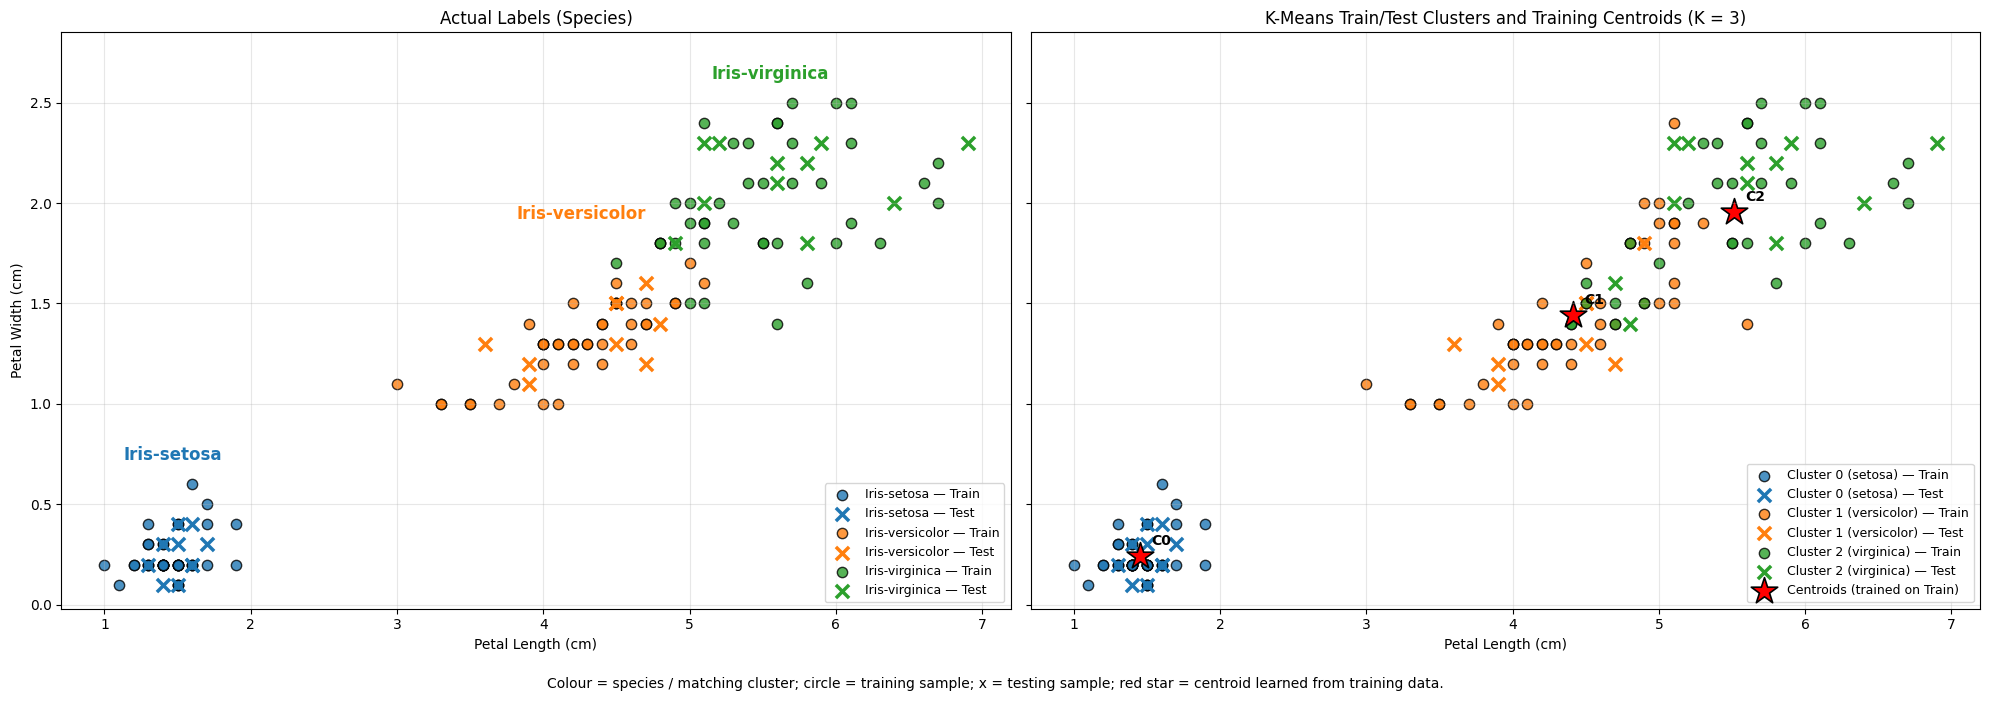

In [258]:
fig, (ax_true, ax_km) = plt.subplots(1, 2, figsize=(20, 7), sharex=True, sharey=True)

# Left: actual labels with species names (train = circle, test = x)
for name in SPECIES_ORDER:
    train_rows = train_indices[species.values[train_indices] == name]
    test_rows = test_indices[species.values[test_indices] == name]
    ax_true.scatter(X.iloc[train_rows]["PetalLengthCm"], X.iloc[train_rows]["PetalWidthCm"],
                    color=SPECIES_COLORS[name], marker="o", s=55, alpha=0.8, edgecolor="black",
                    label=f"{name} — Train")
    ax_true.scatter(X.iloc[test_rows]["PetalLengthCm"], X.iloc[test_rows]["PetalWidthCm"],
                    color=SPECIES_COLORS[name], marker="x", s=90, linewidths=2.5,
                    label=f"{name} — Test")
    # write the species name next to its group
    ax_true.annotate(name, (X.loc[species == name, "PetalLengthCm"].mean(),
                            X.loc[species == name, "PetalWidthCm"].max() + 0.12),
                     ha="center", fontsize=12, fontweight="bold", color=SPECIES_COLORS[name])
ax_true.set_ylim(top=X["PetalWidthCm"].max() + 0.35)   # room for the species names
ax_true.set_title("Actual Labels (Species)")
ax_true.set_xlabel("Petal Length (cm)")
ax_true.set_ylabel("Petal Width (cm)")
ax_true.legend(loc="lower right", fontsize=9)
ax_true.grid(alpha=0.3)

# Right: K-Means clusters
for c in range(K):
    train_rows = train_indices[train_kmeans_labels == c]
    test_rows = test_indices[test_kmeans_labels == c]
    ax_km.scatter(X.iloc[train_rows]["PetalLengthCm"], X.iloc[train_rows]["PetalWidthCm"],
                  color=CLUSTER_COLORS[c], marker="o", s=55, alpha=0.8, edgecolor="black",
                  label=f"{CLUSTER_NAMES[c]} — Train")
    ax_km.scatter(X.iloc[test_rows]["PetalLengthCm"], X.iloc[test_rows]["PetalWidthCm"],
                  color=CLUSTER_COLORS[c], marker="x", s=90, linewidths=2.5,
                  label=f"{CLUSTER_NAMES[c]} — Test")

# Centroids learned from the training set, converted back to cm
centroids_cm = pd.DataFrame(scaler.inverse_transform(kmeans_centers), columns=X.columns)
ax_km.scatter(centroids_cm["PetalLengthCm"], centroids_cm["PetalWidthCm"], marker="*", s=400,
              c="red", edgecolors="black", linewidths=1.2, label="Centroids (trained on Train)")
for c, (cx, cy) in enumerate(zip(centroids_cm["PetalLengthCm"], centroids_cm["PetalWidthCm"])):
    ax_km.annotate(f"C{c}", (cx, cy), xytext=(8, 8), textcoords="offset points", fontweight="bold")

ax_km.set_title(f"K-Means Train/Test Clusters and Training Centroids (K = {K})")
ax_km.set_xlabel("Petal Length (cm)")
ax_km.legend(loc="lower right", fontsize=9)
ax_km.grid(alpha=0.3)

plt.figtext(0.5, 0.01,
            "Colour = species / matching cluster; circle = training sample; x = testing sample; "
            "red star = centroid learned from training data.",
            ha="center", fontsize=10)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

### 7.4 Pairwise Graphs of the K-Means Clusters

K-Means uses all four features, so the clusters are shown for **every pair of features**.
- Off-diagonal plots: one feature against another (circle = train, x = test, red star = centroid).
- Diagonal plots: distribution of each feature within each cluster.

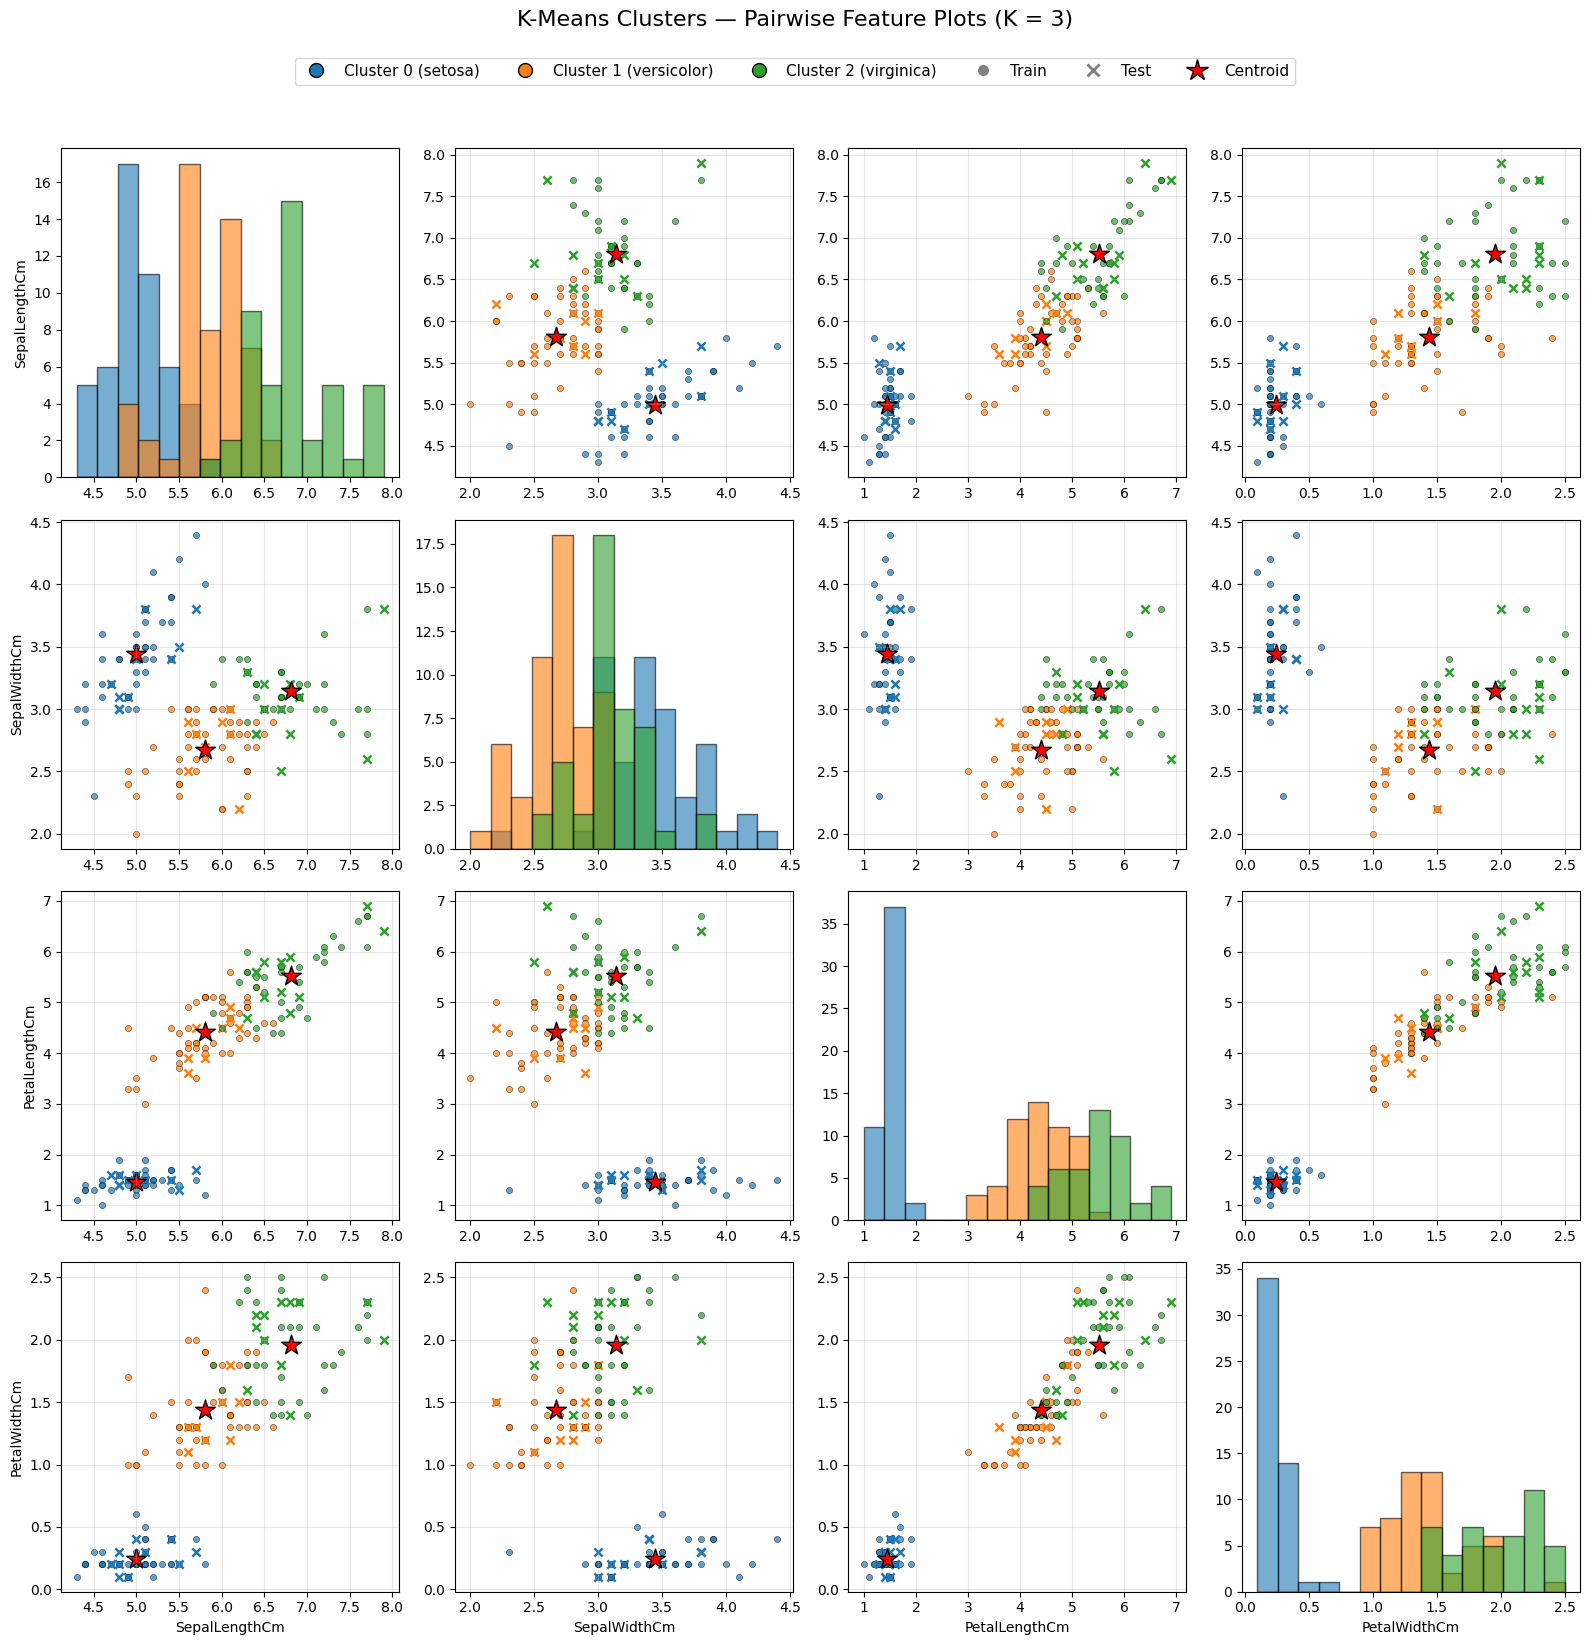

In [259]:
features = X.columns.tolist()
n_features = len(features)

fig, axes = plt.subplots(n_features, n_features, figsize=(16, 16))

for row, feature_y in enumerate(features):
    for col, feature_x in enumerate(features):
        ax = axes[row, col]

        if row == col:
            # Diagonal: histogram of this feature for each cluster (same bins for every cluster)
            bins = np.linspace(X[feature_x].min(), X[feature_x].max(), 16)
            for c in range(K):
                ax.hist(X.loc[kmeans_labels == c, feature_x], bins=bins, alpha=0.6,
                        color=CLUSTER_COLORS[c], edgecolor="black")
        else:
            for c in range(K):
                train_rows = train_indices[train_kmeans_labels == c]
                test_rows = test_indices[test_kmeans_labels == c]
                ax.scatter(X.iloc[train_rows][feature_x], X.iloc[train_rows][feature_y],
                           color=CLUSTER_COLORS[c], marker="o", s=20, alpha=0.7, edgecolor="black", linewidths=0.4)
                ax.scatter(X.iloc[test_rows][feature_x], X.iloc[test_rows][feature_y],
                           color=CLUSTER_COLORS[c], marker="x", s=35, linewidths=1.8)
            ax.scatter(centroids_cm[feature_x], centroids_cm[feature_y], marker="*", s=220,
                       c="red", edgecolors="black", linewidths=1)
            ax.grid(alpha=0.3)

        if row == n_features - 1:
            ax.set_xlabel(feature_x)
        if col == 0:
            ax.set_ylabel(feature_y)

legend_handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=CLUSTER_COLORS[c],
                         markeredgecolor="black", markersize=10, label=CLUSTER_NAMES[c]) for c in range(K)]
legend_handles += [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="grey", markersize=9, label="Train"),
    Line2D([0], [0], marker="x", color="grey", linestyle="", markersize=9, markeredgewidth=2, label="Test"),
    Line2D([0], [0], marker="*", color="w", markerfacecolor="red", markeredgecolor="black",
           markersize=16, label="Centroid"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=6, fontsize=11, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"K-Means Clusters — Pairwise Feature Plots (K = {K})", fontsize=16, y=1.025)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 7.5 Cluster Centroids (original scale)

In [260]:
centroids_cm.index.name = "Cluster"
display(centroids_cm.round(3))

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,4.990,3.440,1.453,0.243
1,5.806,2.672,4.411,1.440
2,6.806,3.142,5.512,1.955


### 7.6 Cluster vs Species and Gini Index

In [261]:
show_species_table(kmeans_labels, "K-Means")

kmeans_gini_table, kmeans_gini = calculate_gini(kmeans_labels, species)
display(kmeans_gini_table.round(4))
print(f"Weighted Gini Index (K-Means): {kmeans_gini:.4f}")

# Gini on the unseen test samples only
_, kmeans_test_gini = calculate_gini(test_kmeans_labels, species.iloc[test_indices])
print(f"Weighted Gini Index on test samples: {kmeans_test_gini:.4f}")

K-Means vs Actual Species:


Species,Iris-setosa,Iris-versicolor,Iris-virginica
Cluster,,,
0,50,0,0
1,0,39,16
2,0,11,34


,Size,Majority Species,Gini
Cluster,,,
0,50,Iris-setosa,0.0000
1,55,Iris-versicolor,0.4126
2,45,Iris-virginica,0.3694


Weighted Gini Index (K-Means): 0.2621
Weighted Gini Index on test samples: 0.1694


## 8. Hierarchical Clustering (Agglomerative)

**Agglomerative** (bottom-up) clustering starts with every point as its own cluster and keeps merging the closest clusters
until **K = 3** clusters remain.

Hierarchical clustering has no `predict()` for new points, so it is run on the complete standardized dataset.

### 8.1 Hierarchical Clustering (K = 3)

**Ward linkage** merges the two clusters that cause the smallest increase in WCSS.

In [262]:
agglo = AgglomerativeClustering(n_clusters=K, metric="euclidean", linkage="ward")
agglo_raw_labels = agglo.fit_predict(X_scaled)

# Fixed cluster numbers/colours: 0 = setosa-like, 1 = versicolor-like, 2 = virginica-like
agglo_labels = align_to_species(agglo_raw_labels)[agglo_raw_labels]

print("Hierarchical cluster sizes:", np.bincount(agglo_labels))

Hierarchical cluster sizes: [49 75 26]


### 8.2 Dendrogram with the 3 Clusters

The dendrogram is built with the same Ward linkage and cut at **K = 3**.
Each branch is coloured with the colour of the cluster it belongs to (the same colours as the scatter plots),
and each cluster is labelled with its number, size and majority species.

In [263]:
linkage_matrix = linkage(X_scaled, method="ward")
n_samples = len(X_scaled)

# Cut height = midpoint between the merge that leaves 3 clusters and the merge that leaves 2
merge_distances = np.sort(linkage_matrix[:, 2])[::-1]
cut_height = (merge_distances[K - 2] + merge_distances[K - 1]) / 2
print(f"Cut height for {K} clusters: {cut_height:.3f}")

# Samples under every node of the tree (leaves are 0..n-1, merged nodes are n, n+1, ...)
node_members = [[i] for i in range(n_samples)]
for a, b, _, _ in linkage_matrix:
    node_members.append(node_members[int(a)] + node_members[int(b)])


def link_color(node_id):
    # A branch gets a cluster colour if all its samples are in one cluster; merges above the cut are grey
    clusters_in_node = np.unique(agglo_labels[node_members[node_id]])
    return CLUSTER_COLORS[clusters_in_node[0]] if len(clusters_in_node) == 1 else "grey"

Cut height for 3 clusters: 10.496


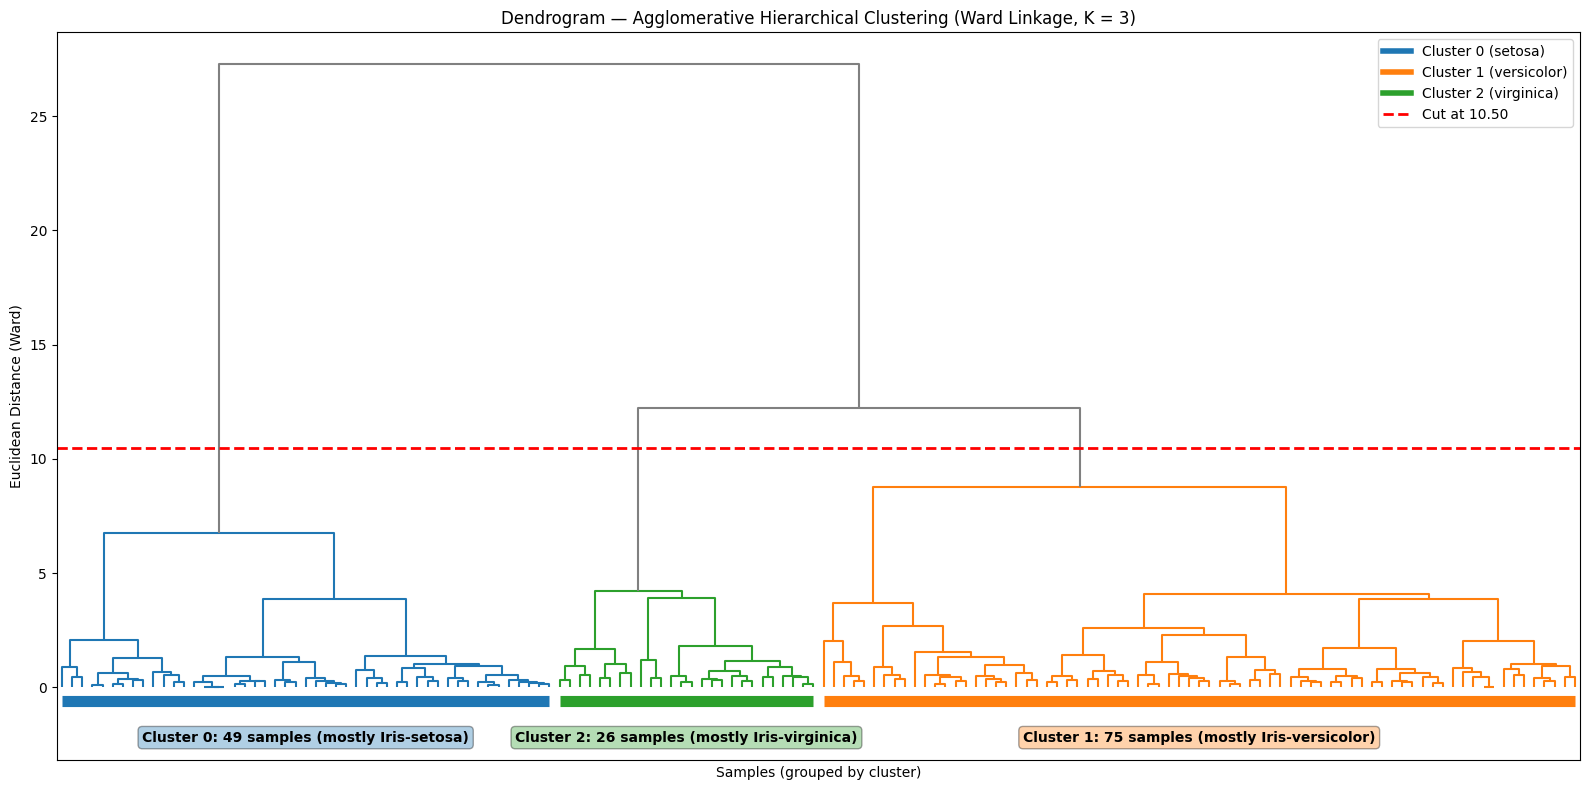

In [264]:
fig, ax = plt.subplots(figsize=(16, 8))
dendro = dendrogram(linkage_matrix, link_color_func=link_color, no_labels=True, ax=ax)
ax.axhline(cut_height, color="red", linestyle="--", linewidth=2, label=f"Cut at {cut_height:.2f} → {K} clusters")

# Leaf i is drawn at x = 5 + 10 * position; label each cluster above the middle of its leaves
leaf_order = np.array(dendro["leaves"])
for c in range(K):
    positions = np.where(agglo_labels[leaf_order] == c)[0]
    x_mid = 5 + 10 * positions.mean()
    majority = species[agglo_labels == c].value_counts().idxmax()
    ax.text(x_mid, -2.2, f"Cluster {c}: {len(positions)} samples (mostly {majority})",
            ha="center", va="center", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round", facecolor=CLUSTER_COLORS[c], alpha=0.35))
    # coloured bar under the leaves of this cluster
    ax.plot([5 + 10 * positions.min(), 5 + 10 * positions.max()], [-0.6, -0.6],
            color=CLUSTER_COLORS[c], linewidth=8, solid_capstyle="butt")

handles = [Line2D([0], [0], color=CLUSTER_COLORS[c], linewidth=4, label=CLUSTER_NAMES[c]) for c in range(K)]
handles.append(Line2D([0], [0], color="red", linestyle="--", linewidth=2, label=f"Cut at {cut_height:.2f}"))
ax.legend(handles=handles, loc="upper right")
ax.set_ylim(bottom=-3.2)
ax.set_title("Dendrogram — Agglomerative Hierarchical Clustering (Ward Linkage, K = 3)")
ax.set_xlabel("Samples (grouped by cluster)")
ax.set_ylabel("Euclidean Distance (Ward)")
plt.tight_layout()
plt.show()

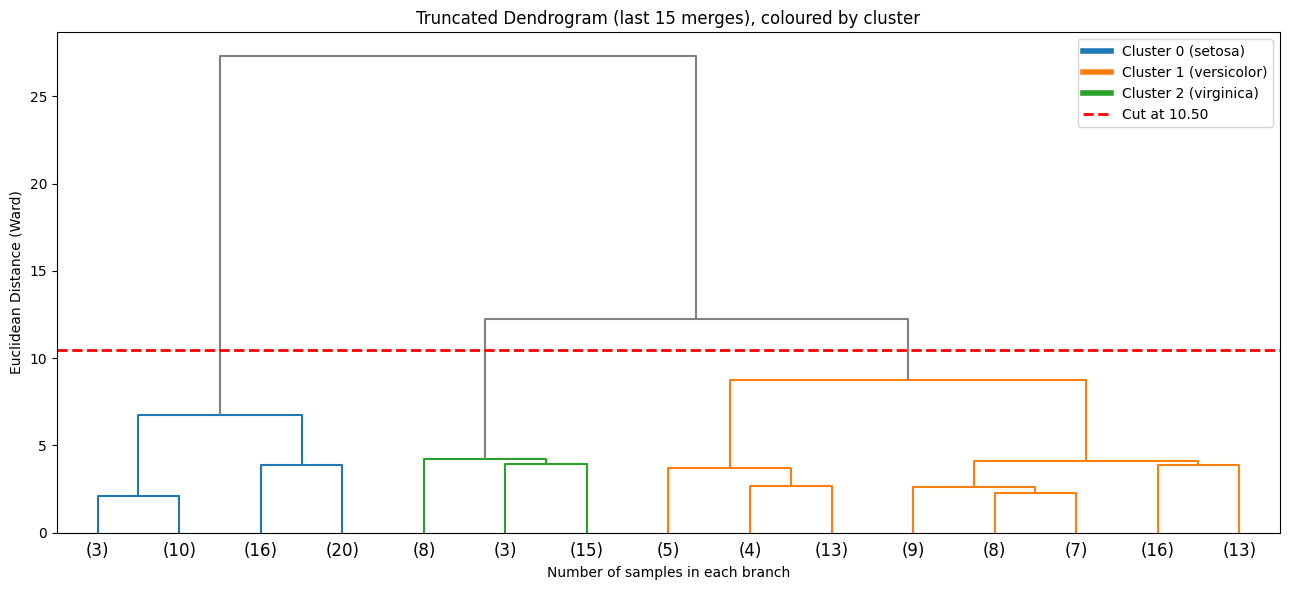

In [265]:
# Truncated dendrogram: last 15 merges only, easier to read. Leaf labels show how many samples are under each branch.
fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(linkage_matrix, truncate_mode="lastp", p=15, show_leaf_counts=True,
           link_color_func=link_color, ax=ax)
ax.axhline(cut_height, color="red", linestyle="--", linewidth=2)
ax.legend(handles=handles, loc="upper right")
ax.set_title("Truncated Dendrogram (last 15 merges), coloured by cluster")
ax.set_xlabel("Number of samples in each branch")
ax.set_ylabel("Euclidean Distance (Ward)")
plt.tight_layout()
plt.show()

### 8.3 Show Hierarchical Clusters

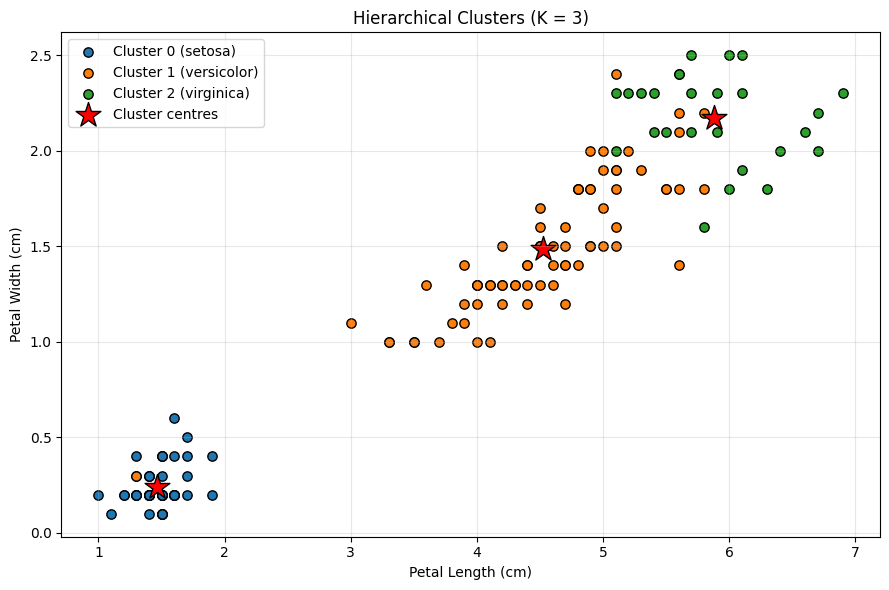

Hierarchical vs Actual Species:


Species,Iris-setosa,Iris-versicolor,Iris-virginica
Cluster,,,
0,49,0,0
1,1,50,24
2,0,0,26


,Size,Majority Species,Gini
Cluster,,,
0,49,Iris-setosa,0.000
1,75,Iris-versicolor,0.453
2,26,Iris-virginica,0.000


Weighted Gini Index (Hierarchical): 0.2265


In [266]:
agglo_centers = np.array([X_scaled[agglo_labels == c].mean(axis=0) for c in range(K)])
show_clusters(agglo_labels, f"Hierarchical Clusters (K = {K})", centers=agglo_centers)

show_species_table(agglo_labels, "Hierarchical")
agglo_gini_table, agglo_gini = calculate_gini(agglo_labels, species)
display(agglo_gini_table.round(4))
print(f"Weighted Gini Index (Hierarchical): {agglo_gini:.4f}")

## 9. Compare the Clustering Methods

All metrics are calculated on the complete standardized dataset with K = 3.
- **WCSS:** lower = more compact clusters
- **Weighted Gini:** lower = purer clusters (fewer species mixed together)
- **Dunn Index:** higher = better separated clusters

In [267]:
all_labels = {
    "K-Means": kmeans_labels,
    "Hierarchical": agglo_labels,
}

comparison = pd.DataFrame([
    {
        "Method": name,
        "Clusters": K,
        "WCSS": calculate_wcss(X_scaled, labels),
        "Weighted Gini": calculate_gini(labels, species)[1],
        "Dunn Index": dunn_index(X_scaled, labels),
    }
    for name, labels in all_labels.items()
]).set_index("Method")

display(comparison.round(4))

,Clusters,WCSS,Weighted Gini,Dunn Index
Method,,,,
K-Means,3,138.3016,0.2621,0.0577
Hierarchical,3,152.5060,0.2265,0.0918


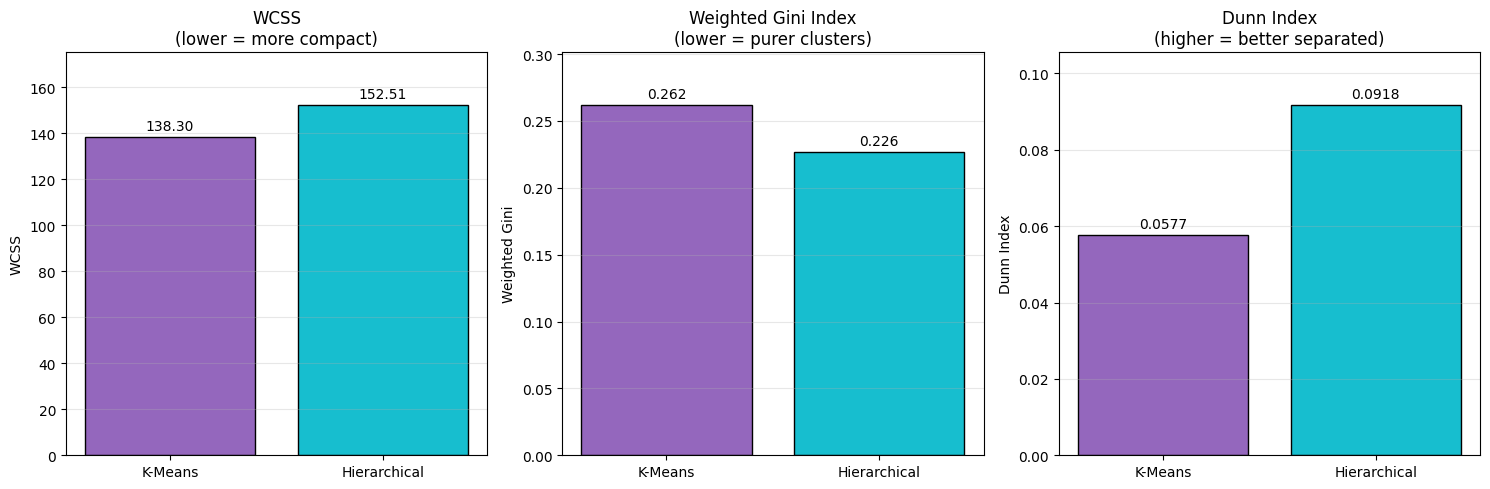

In [268]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = [
    ("WCSS", "WCSS\n(lower = more compact)", "%.2f"),
    ("Weighted Gini", "Weighted Gini Index\n(lower = purer clusters)", "%.3f"),
    ("Dunn Index", "Dunn Index\n(higher = better separated)", "%.4f"),
]
for ax, (column, title, fmt) in zip(axes, metrics):
    bars = ax.bar(comparison.index, comparison[column], color=["tab:purple", "tab:cyan"],
                  edgecolor="black")
    ax.bar_label(bars, fmt=fmt, padding=3)
    ax.set_title(title)
    ax.set_ylabel(column)
    ax.set_ylim(0, comparison[column].max() * 1.15)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

,K-Means,Hierarchical
Majority Species,,
Iris-setosa,0.0000,0.000
Iris-versicolor,0.4126,0.453
Iris-virginica,0.3694,0.000


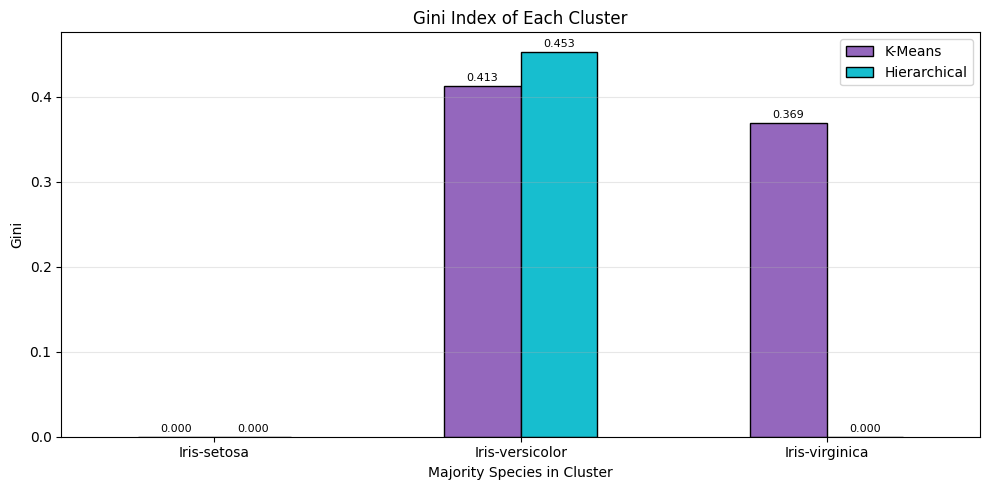

In [269]:
# Gini of each cluster, labelled by the species it mostly contains
gini_per_cluster = pd.DataFrame({
    "K-Means": kmeans_gini_table.set_index("Majority Species")["Gini"],
    "Hierarchical": agglo_gini_table.set_index("Majority Species")["Gini"],
})
display(gini_per_cluster.round(4))

ax = gini_per_cluster.plot(kind="bar", figsize=(10, 5), edgecolor="black", color=["tab:purple", "tab:cyan"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
ax.set_title("Gini Index of Each Cluster")
ax.set_xlabel("Majority Species in Cluster")
ax.set_ylabel("Gini")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 9.1 Side-by-Side Clusters

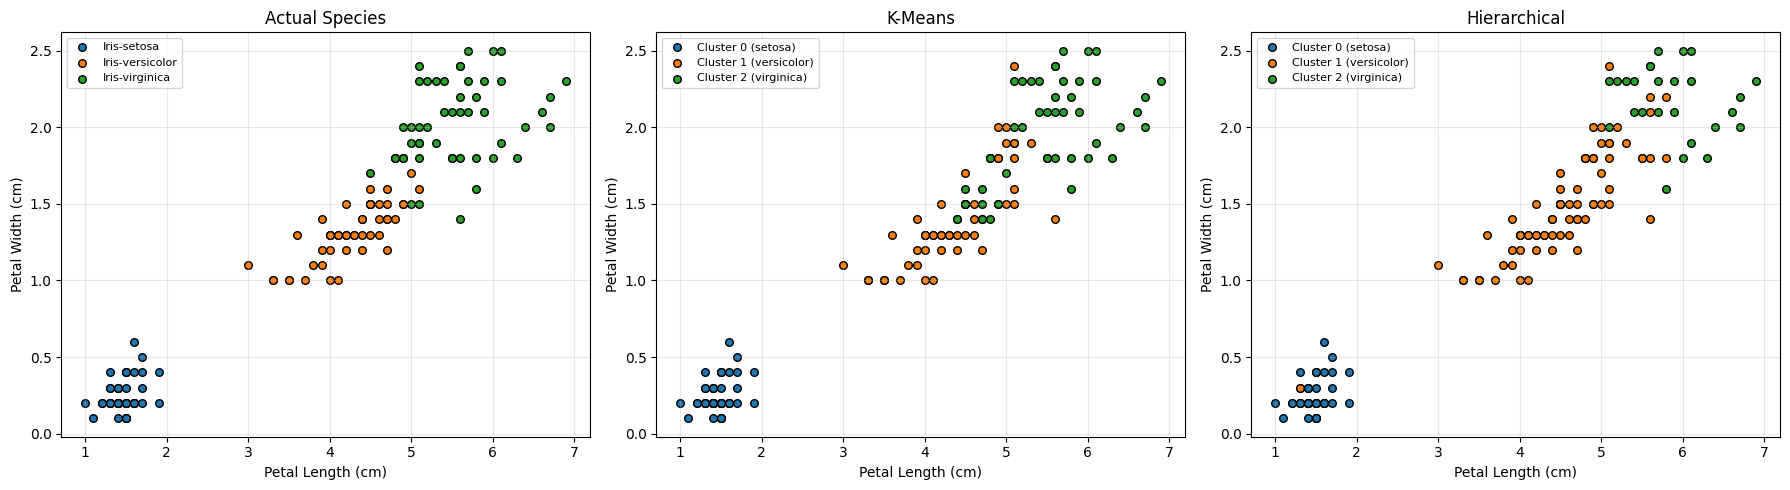

In [270]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ["Actual Species"] + list(all_labels)):
    if name == "Actual Species":
        for s in SPECIES_ORDER:
            ax.scatter(X.loc[species == s, "PetalLengthCm"], X.loc[species == s, "PetalWidthCm"],
                       color=SPECIES_COLORS[s], s=30, edgecolor="black", label=s)
    else:
        labels = all_labels[name]
        for c in range(K):
            ax.scatter(X.loc[labels == c, "PetalLengthCm"], X.loc[labels == c, "PetalWidthCm"],
                       color=CLUSTER_COLORS[c], s=30, edgecolor="black", label=CLUSTER_NAMES[c])
    ax.set_title(name)
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Final Conclusion

In [271]:
print("Most compact clusters (lowest WCSS)         :", comparison["WCSS"].idxmin())
print("Purest clusters (lowest weighted Gini)      :", comparison["Weighted Gini"].idxmin())
print("Best separated clusters (highest Dunn Index):", comparison["Dunn Index"].idxmax())

Most compact clusters (lowest WCSS)         : K-Means
Purest clusters (lowest weighted Gini)      : Hierarchical
Best separated clusters (highest Dunn Index): Hierarchical


- The **Elbow Method** selects **K = 3** for K-Means; it is highlighted on the graph.
- K-Means is trained on the **training split**; test samples are assigned to the nearest learned centroid.
- The **Dendrogram** is cut at **K = 3**, and each of the 3 clusters is coloured and labelled on the tree.
- **Hierarchical (Agglomerative, Ward)** clustering is implemented with K = 3.
- **WCSS:** K-Means gives the more compact clusters, because K-Means directly minimises WCSS.
- **Gini Index:** the setosa cluster is pure (Gini = 0) in every method; versicolor and virginica overlap, so their clusters are mixed.
- **Gini and Dunn:** Hierarchical gives the purer and better-separated clusters: it isolates a pure virginica cluster, but puts the remaining virginica together with versicolor.
- **Real-world insight:** setosa is clearly different from the other two species (much smaller petals), while
  versicolor and virginica are similar and are partly mixed by every algorithm.